# El generador sintético basado en árbol, paso a paso

Este notebook explica **en detalle** cómo `tree_generator.py` convierte un mapa de etiquetas (una segmentación) en un número ilimitado de pares *(imagen sintética, segmentación)* para entrenar una red de segmentación que no dependa del contraste ni de la resolución.

La idea viene de **SynthSeg** (Billot et al.): si durante el entrenamiento la red ve imágenes con contrastes, formas, resoluciones y artefactos aleatorios, aprende a segmentar *la anatomía* y no un tipo concreto de resonancia. La diferencia de este generador es que las intensidades no se sortean de forma independiente para cada tejido, sino a partir de un **árbol de etiquetas** (una ontología): tejidos parecidos reciben intensidades parecidas y, a una resolución gruesa, las estructuras que no se pueden distinguir se **fusionan** y comparten la misma intensidad.

Cada sección tiene la misma estructura:
1. **Concepto**: qué hace el paso y por qué hace falta.
2. **Ejemplo de juguete**: un volumen pequeño y fácil de mirar, donde se ve el mecanismo.
3. **El paso real**: el mismo código aplicado al template real (cerebro completo).

### Índice
0. Preparación
1. Datos de entrada
2. El árbol de etiquetas y el modelo de intensidades
3. Superresolución de etiquetas (offline)
4. El generador: espacio de etiquetas
5. Erosión / dilatación aleatoria
6. Deformación afín + elástica
7. Volumen parcial (*partial volume*)
8. Intensidades del árbol y fusión de tejidos según la resolución
9. Artefactos: campo de sesgo, movimiento, ruido, normalización
10. Todo junto: `gen()`, guardar muestras y usar los grupos en la *loss*
11. Resumen de parámetros y limitaciones

### Vista general del pipeline

```
                 OFFLINE (una vez por template)                      ONLINE (cada muestra)
 seg 1 mm ──► [1] etiquetas crudas ──► [2] superresolución ──► template 0.25 mm
                                                                     │
                     ┌───────────────────────────────────────────────┘
                     ▼                         resolución 0.25 mm (HR)
              [3] erosión/dilatación ──► [4] deformación afín+elástica
                                                    │
                                                    ▼  0.25 mm ─► 0.75 mm
                                         [5] volumen parcial  ──────────────► segmentación 0.75 mm
                                                    │
                                                    ▼                         resolución 0.75 mm
              [6] intensidades del árbol: imagen = Σ_g pv_g · N(μ_g, σ_g)
                                                    │
                                                    ▼
              [7] campo de sesgo ─► movimiento ─► ruido ─► min-max [0,1] ───► imagen 0.75 mm
```

Hay dos rejillas (*grids*):
- **HR** (*high resolution*), 0.25 mm: donde se manipulan las **formas** (pasos 3–4). Trabajar a una resolución 3 veces más fina que la de entrenamiento permite que los bordes entre tejidos queden en posiciones *sub-vóxel*.
- **LR / entrenamiento**, 0.75 mm: donde se generan las **intensidades** y los artefactos (pasos 6–7). Cada vóxel LR contiene exactamente `factor³ = 3³ = 27` vóxeles HR.

## 0. Preparación

Importamos el módulo del generador (`tree_generator`) y el del árbol (`tree_sampling`), y algunas funciones de visualización de `run_example.py`. Elegimos la GPU con más memoria libre: el template HR tiene ~500 millones de vóxeles.

In [1]:
import json
import math
import os
import random
import tempfile

import matplotlib
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import torch
import torch.nn.functional as F

import tree_generator as tg
from tree_sampling import LabelTree, TreeSampling
from run_example import axial, show, random_label_cmap
from local_cornucopia import cornucopia as cc
from local_cornucopia.cornucopia.utils import warps

%matplotlib inline
plt.rcParams['figure.dpi'] = 90

if torch.cuda.is_available():
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    DEVICE = f'cuda:{int(np.argmax(free))}'
else:
    DEVICE = 'cpu'
print('device:', DEVICE)

SEG = 'data/inputs/seg.nii.gz'
T1 = 'data/inputs/T1w.nii.gz'
TREE = 'data/inputs/synthseg_ctx_tree.json'
CONFIG = 'configs/freesurfer.json'
CACHE = 'data/outputs/templates'

tg.seed_everything(0)   # random, numpy y torch: el notebook es reproducible

device: cuda:3


In [2]:
# Funciones auxiliares que usaremos en todo el notebook

def explained_variance(img, seg):
    """Fracción de la varianza de la imagen explicada por la segmentación (1 = cada
    etiqueta tiene una intensidad constante). Sirve para comprobar que imagen y
    segmentación están alineadas."""
    img = np.asarray(img, dtype=float).ravel()
    seg = np.asarray(seg).ravel()
    within = 0.
    for l in np.unique(seg):
        v = img[seg == l]
        within += v.size * v.var()
    return 1 - within / (img.size * img.var())


def mid(vol, z=None):
    """Corte z (por defecto el central) de un volumen de juguete, para mostrarlo."""
    vol = vol.detach().cpu().numpy() if torch.is_tensor(vol) else np.asarray(vol)
    return vol[:, :, vol.shape[2] // 2 if z is None else z].T


def row(images, titles, cmaps=None, size=3.0, **kw):
    """Una fila de imágenes con título."""
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    axes = np.atleast_1d(axes)
    for i, (ax, im, t) in enumerate(zip(axes, images, titles)):
        cm = (cmaps[i] if isinstance(cmaps, (list, tuple)) else cmaps) or 'gray'
        k = kw if not isinstance(cmaps, (list, tuple)) or cmaps[i] != 'gray' else {}
        ax.imshow(im, cmap=cm, interpolation='nearest', origin='lower', **k)
        ax.set_title(t, fontsize=9)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

### La configuración

Todos los parámetros del generador están en la *dataclass* `TreeGeneratorConfig`. Los valores por defecto están en `tree_generator.py`; `configs/freesurfer.json` sólo sobrescribe algunos campos:
- `morpho_pairs`: las parejas de tejidos que se erosionan/dilatan (paso 3),
- `unassigned: "background"`: etiquetas del template que no están en el árbol se envían al fondo,
- `contrasts`: lista de contrastes entre los que se sortea uno por imagen,
- `resolution: [0.75, 3.0]`: rango del que se sortea, por imagen, la resolución que decide qué tejidos se fusionan (sección 8).

Iremos explicando cada campo en el paso donde se usa.

In [3]:
cfg = tg.TreeGeneratorConfig.from_json(CONFIG)
print(open(CONFIG).read())
cfg

{
  "morpho_pairs": [
    ["cerebral_wm", "cortex"],
    ["cerebral_wm", "lateral_ventricles"],
    ["cerebral_wm", "inf_lat_ventricles"],
    ["cerebral_wm", "thalamus"],
    ["cerebral_wm", "putamen"],
    ["cerebral_wm", "pallidum"],
    ["cerebral_wm", "caudate"],
    ["cerebral_wm", "accumbens"],
    ["cerebral_wm", "amygdala"],
    ["cerebral_wm", "hippocampus"],
    [24, "cortex"],
    [24, "vessels"]
  ],
  "unassigned": "background",
  "contrasts": ["T1", "T2", "FLAIR", "PD"],
   "resolution": [0.75, 3.0]
}



TreeGeneratorConfig(target_voxel=0.75, factor=3, background=0, output_labels='templates', unassigned='background', morpho_pairs=(['cerebral_wm', 'cortex'], ['cerebral_wm', 'lateral_ventricles'], ['cerebral_wm', 'inf_lat_ventricles'], ['cerebral_wm', 'thalamus'], ['cerebral_wm', 'putamen'], ['cerebral_wm', 'pallidum'], ['cerebral_wm', 'caudate'], ['cerebral_wm', 'accumbens'], ['cerebral_wm', 'amygdala'], ['cerebral_wm', 'hippocampus'], [24, 'cortex'], [24, 'vessels']), morpho_iter=(1, 4), morpho_prob=0.5, rotations=10.0, zooms=0.1, shears=0.0, translations_mm=0.0, elastic_dmax_mm=7.5, elastic_ctrl=7, colors_mu=(0.0, 255.0), colors_sigma=(0.255, 2.55), min_sigma=0.0, intensity_scale=255.0, resolution=(0.75, 3.0), contrasts=['T1', 'T2', 'FLAIR', 'PD'], bias_prob=1.0, bias_vmax=0.5, bias_ctrl=5, motion_prob=0.3, motion_shots=3, motion_rotations=10.0, motion_translations_mm=10.0, noise_sigma=(0.01, 0.1))

## 1. Datos de entrada

El generador sólo necesita **mapas de etiquetas** (segmentaciones). La imagen T1 real sólo se usa aquí para comparar: el generador **nunca** mira intensidades reales.

La segmentación sigue la convención de **FreeSurfer** (`FreeSurferColorLUT.txt`): cada valor entero es una estructura. Por ejemplo:

| valor | estructura | valor | estructura |
|---|---|---|---|
| 0 | fondo | 2 / 41 | sustancia blanca cerebral izq. / der. |
| 3 / 42 | corteza izq. / der. | 4 / 43 | ventrículo lateral izq. / der. |
| 10 / 49 | tálamo izq. / der. | 17 / 53 | hipocampo izq. / der. |
| 24 | LCR | 1001–1035 / 2001–2035 | parcelas corticales (Desikan-Killiany) izq. / der. |

In [4]:
t1 = nib.load(T1)
seg = nib.load(SEG)
seg_raw = np.asarray(seg.dataobj).astype(int)
values, counts = np.unique(seg_raw, return_counts=True)

print('forma:', seg_raw.shape, ' tamaño de vóxel (mm):', seg.header.get_zooms()[:3])
print(f'{len(values)} etiquetas distintas (incluido el fondo)')
print('primeras etiquetas:', values[:25].tolist())
print('affine (vóxel -> mundo, en mm):\n', np.round(seg.affine, 2))

forma: (197, 233, 189)  tamaño de vóxel (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
99 etiquetas distintas (incluido el fondo)
primeras etiquetas: [0, 2, 4, 5, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 24, 26, 28, 41, 43, 44, 46, 47, 49, 50]
affine (vóxel -> mundo, en mm):
 [[   1.    0.   -0.  -98.]
 [   0.    1.   -0. -134.]
 [   0.    0.    1.  -72.]
 [   0.    0.    0.    1.]]


La **matriz affine** (4×4) convierte índices de vóxel `(i, j, k)` en coordenadas del mundo en mm: `x_mundo = A · (i, j, k, 1)ᵀ`. La diagonal es el tamaño de vóxel (con el signo de la orientación) y la última columna, la posición del vóxel `(0,0,0)`. Cuando recortamos o cambiamos la resolución de un volumen, ajustamos esta matriz para que **cada vóxel siga en el mismo lugar del mundo**. Gracias a ello podemos mostrar siempre el mismo corte axial (a través de los tálamos) aunque los volúmenes tengan resoluciones y recortes distintos: `axial(vol, affine, punto)` busca el corte que pasa por un punto del mundo.

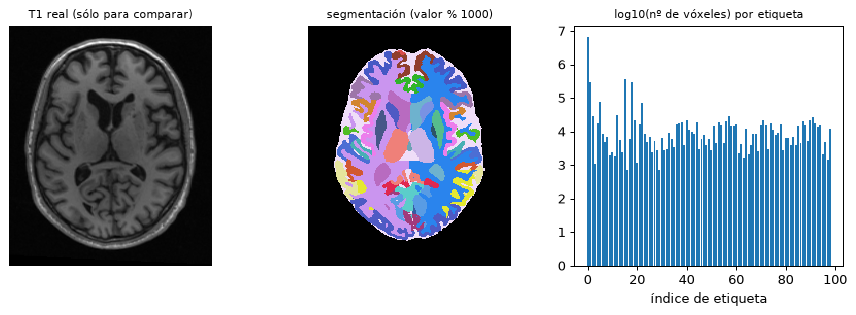

In [5]:
thal = np.argwhere(np.isin(seg_raw, [10, 49])).mean(0)     # centro de los tálamos (vóxeles)
point = (seg.affine @ np.append(thal, 1))[:3]               # ... en mm (mundo)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
show(axes[0], axial(t1.get_fdata(), t1.affine, point), 'T1 real (sólo para comparar)')
show(axes[1], axial(seg_raw % 1000, seg.affine, point), 'segmentación (valor % 1000)',
     cmap=random_label_cmap(1000))
axes[2].bar(range(len(values)), np.log10(counts))
axes[2].set_title('log10(nº de vóxeles) por etiqueta', fontsize=9)
axes[2].set_xlabel('índice de etiqueta')
fig.tight_layout()
plt.show()

## 2. El árbol de etiquetas y el modelo de intensidades

### 2.1 Conceptos

El árbol (`synthseg_ctx_tree.json`) es una **ontología**: organiza las estructuras de lo general a lo particular. Cada nodo tiene:

| campo | significado |
|---|---|
| `parent`, `children`, `level` | posición en el árbol (raíz = nivel 0) |
| `labels` | valores del mapa de etiquetas que se pintan con la gaussiana de este nodo |
| `w_mu`, `w_sigma` | **sólo nivel 1**: pesos de los *colores principales* (suman 1) |
| `wr_mu`, `wr_sigma` | amplitud de la perturbación aleatoria respecto al padre |
| `r_max` | resolución más gruesa (mm) a la que el nodo es **visible**; puede depender del contraste |
| `null` | color nulo (μ = σ = 0), heredado por todo el subárbol (p. ej. el fondo) |

**Colores principales.** El árbol define `N` colores principales, aquí `GM`, `WM` y `CSF` (sustancia gris, blanca y líquido). Para cada imagen se sortean sus medias `C ~ U(0, 255)` y desviaciones `V ~ U(0.255, 2.55)`. Como `C` es aleatorio, a veces la WM es más clara que la GM (aspecto T1), a veces más oscura (aspecto T2), etc.: **el contraste no se fija, se sortea**.

**Reglas de muestreo** para una imagen a resolución `r` y contraste `c`:

- **Nivel 1** (grandes clases de tejido): mezcla de colores principales más una perturbación
  $$\mu = \sum_i w^{\mu}_i\,C_i + w_r^{\mu}\,\varepsilon_1, \qquad \sigma = \sum_i w^{\sigma}_i\,V_i + w_r^{\sigma}\,\varepsilon_2, \qquad \varepsilon \sim \mathcal N(0,1)$$
  Por ejemplo el tálamo podría tener `w_mu = [0.5, 0.5, 0]`: su intensidad queda entre la GM y la WM.
- **Nivel ≥ 2** (subestructuras): si el nodo es **visible**, hereda la gaussiana del padre y la perturba un poco
  $$\mu = \mu_{padre} + w_r^{\mu}\,\varepsilon_1, \qquad \sigma = \sigma_{padre} + w_r^{\sigma}\,\varepsilon_2$$
  y si **no es visible**, toma **exactamente** la gaussiana del padre: se *fusiona* con él.
- Un nodo es visible si `r ≤ r_max(c)` **y** su padre es visible. Así, cuando un nodo colapsa, todo su subárbol colapsa con él. Los nodos de nivel 1 siempre son visibles.

La intuición: una parcela subcortical cortical (p. ej. hipocampal sub strcutures) tiene en la realidad la misma intensidad que el resto del hopocampo más una pequeña variación; y a 3 mm de resolución las estrcuturas ya no se pueden distinguir por intensidad, así que no tiene sentido darles intensidades distintas (ni pedirle a la red que las separe).

### 2.2 Un árbol de juguete

Construimos un árbol mínimo con la API programática (`LabelTree.new` + `add_node`), para ver cada regla aislada:

In [6]:
toy_tree = LabelTree.new(['GM', 'WM', 'CSF'])
toy_tree.add_node('background', 'root', labels=[0], null=True)
toy_tree.add_node('wm', 'root', labels=[1], w_mu=[0, 1, 0], wr_mu=4, wr_sigma=0.5)
toy_tree.add_node('gm', 'root', labels=[], w_mu=[1, 0, 0], wr_mu=4, wr_sigma=0.5)
toy_tree.add_node('gm_a', 'gm', labels=[3], wr_mu=12, wr_sigma=0.5, r_max=1.0)  # visibles hasta 1 mm
toy_tree.add_node('gm_b', 'gm', labels=[4], wr_mu=12, wr_sigma=0.5, r_max=1.0)
toy_tree.add_node('csf', 'root', labels=[5], w_mu=[0, 0, 1], wr_mu=4, wr_sigma=0.5)
toy_tree.add_node('deep_gm', 'root', labels=[6], w_mu=[0.5, 0.5, 0], wr_mu=4, wr_sigma=0.5)
toy_tree.validate()

print('--- a 0.75 mm ---')
toy_tree.print_tree(0.75)
print('\n--- a 2 mm ---')
toy_tree.print_tree(2.0)
print('\ngrupos de etiquetas a 0.75 mm:', toy_tree.label_groups(0.75))
print('grupos de etiquetas a 2 mm   :', toy_tree.label_groups(2.0))

--- a 0.75 mm ---
root [L0, r_max=inf, visible]
    background [L1, r_max=inf, visible] labels=[0]
    wm [L1, r_max=inf, visible] labels=[1]
    gm [L1, r_max=inf, visible]
        gm_a [L2, r_max=1, visible] labels=[3]
        gm_b [L2, r_max=1, visible] labels=[4]
    csf [L1, r_max=inf, visible] labels=[5]
    deep_gm [L1, r_max=inf, visible] labels=[6]

--- a 2 mm ---
root [L0, r_max=inf, visible]
    background [L1, r_max=inf, visible] labels=[0]
    wm [L1, r_max=inf, visible] labels=[1]
    gm [L1, r_max=inf, visible]
        gm_a [L2, r_max=1, -> gm] labels=[3]
        gm_b [L2, r_max=1, -> gm] labels=[4]
    csf [L1, r_max=inf, visible] labels=[5]
    deep_gm [L1, r_max=inf, visible] labels=[6]

grupos de etiquetas a 0.75 mm: {'background': [0], 'wm': [1], 'gm_a': [3], 'gm_b': [4], 'csf': [5], 'deep_gm': [6]}
grupos de etiquetas a 2 mm   : {'background': [0], 'wm': [1], 'gm': [3, 4], 'csf': [5], 'deep_gm': [6]}


A 2 mm, `gm_a` y `gm_b` dejan de ser visibles (`-> gm`): sus etiquetas 3 y 4 forman **un solo grupo** con una sola gaussiana. Este grupo es también lo que la red debería predecir a esa resolución (ver sección 10).

`TreeSampling` aplica las reglas y devuelve, para cada etiqueta, su `(μ, σ)`. Usamos los mismos colores principales a 0.75 mm y a 2 mm. Dos instancias con la misma semilla sortean los mismos `ε` (el código sortea dos números por nodo aunque el nodo colapse, justamente para que esta comparación sea posible):

In [7]:
toy_labels = [0, 1, 3, 4, 5, 6]
C = np.array([90., 160., 30.])      # GM, WM, CSF  (aspecto T1: WM > GM > CSF)
V = np.array([1.5, 1.0, 2.0])

for res in (0.75, 2.0):
    s = TreeSampling(toy_labels, toy_tree, std_noise=0., seed=1, verbose=False)
    mus, sigmas = s.compute_stats(C, V, res)
    print(f'res {res} mm:  ' + '  '.join(
        f'{l}:{toy_tree.label_to_node[l]}=({m:5.1f},{sd:.2f})'
        for l, m, sd in zip(toy_labels, mus, sigmas)))

res 0.75 mm:  0:background=(  0.0,0.00)  1:wm=(161.3,0.35)  3:gm_a=( 94.0,2.00)  4:gm_b=( 84.8,1.64)  5:csf=( 27.9,2.29)  6:deep_gm=(126.5,1.40)
res 2.0 mm:  0:background=(  0.0,0.00)  1:wm=(161.3,0.35)  3:gm_a=( 93.6,1.72)  4:gm_b=( 93.6,1.72)  5:csf=( 27.9,2.29)  6:deep_gm=(126.5,1.40)


Observaciones:
- el fondo (`null`) vale 0;
- `wm` ≈ `C[WM]` = 160, `csf` ≈ `C[CSF]` = 30, y `deep_gm` ≈ (90 + 160)/2 = 125: es la mezcla de colores principales, más la perturbación `wr_mu · ε`;
- a 0.75 mm, `gm_a` y `gm_b` se separan de `gm` (`wr_mu = 12`); a 2 mm tienen **exactamente** la misma gaussiana.

Ahora pintamos un mapa de juguete con varios sorteos de colores principales. Cada sorteo da un "contraste" diferente:

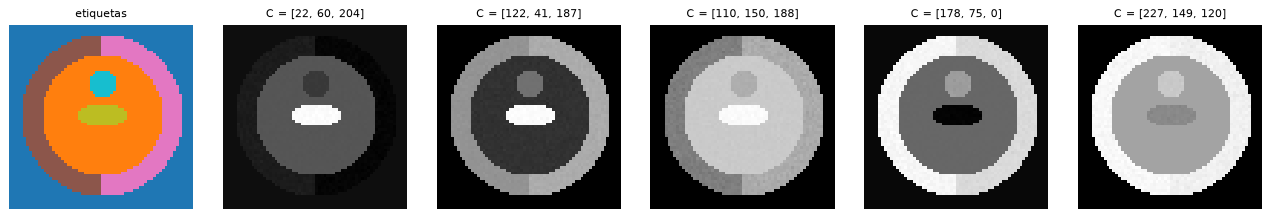

In [8]:
# mapa de juguete 2D: corteza (dos mitades, gm_a/gm_b), WM, ventrículo, núcleo gris
n = 64
yy, xx = np.meshgrid(np.arange(n), np.arange(n), indexing='ij')
r = np.hypot(xx - n / 2, yy - n / 2)
toy2d = np.zeros((n, n), int)
toy2d[r < 28] = np.where(xx[r < 28] < n / 2, 3, 4)
toy2d[r < 21] = 1
toy2d[((xx - n / 2) / 9) ** 2 + ((yy - n / 2) / 4) ** 2 < 1] = 5
toy2d[np.hypot(xx - n / 2, yy - n / 2 - 11) < 5] = 6

rng = np.random.default_rng(3)
imgs, titles = [toy2d], ['etiquetas']
s = TreeSampling(toy_labels, toy_tree, std_noise=0., seed=0, verbose=False)
for k in range(5):
    Ck, Vk = rng.uniform(0, 255, 3), rng.uniform(0.255, 2.55, 3)
    imgs.append(s.sample_image(toy2d, Ck, Vk, resolution=0.75))
    titles.append(f'C = {np.round(Ck).astype(int).tolist()}')
row(imgs, titles, ['tab10'] + ['gray'] * 5, size=2.4)

### 2.3 El árbol real

El árbol `synthseg_ctx_tree.json` tiene 65 nodos: las clases de nivel 1 (WM cerebral, corteza, espacios de LCR, núcleos grises profundos, …) y, debajo, sus subestructuras (p. ej. las 34 parcelas corticales bajo `cortex`). El `r_max` decide hasta qué resolución sobrevive cada una.

In [9]:
tree = LabelTree.load(TREE)
print('colores principales:', tree.colors, ' contrastes:', tree.contrasts)
print(f'{len(tree.nodes)} nodos, {len(tree.label_to_node)} etiquetas\n')
tree.print_tree(0.75)

colores principales: ['GM', 'WM', 'CSF']  contrastes: ['T1', 'T2', 'FLAIR', 'PD']
65 nodos, 111 etiquetas

root [L0, r_max=inf, visible]
    background [L1, r_max=inf, visible] labels=[0]
    cerebral_wm [L1, r_max=inf, visible] labels=[2, 41]
        wm_lesions [L2, r_max=2, visible] labels=[25, 57]
        optic_chiasm [L2, r_max=1.5, visible] labels=[85]
    cortex [L1, r_max=inf, visible] labels=[3, 42]
        cortex_1001_2001 [L2, r_max=1, visible] labels=[1001, 2001]
        cortex_1002_2002 [L2, r_max=1, visible] labels=[1002, 2002]
        cortex_1003_2003 [L2, r_max=1, visible] labels=[1003, 2003]
        cortex_1005_2005 [L2, r_max=1, visible] labels=[1005, 2005]
        cortex_1006_2006 [L2, r_max=1, visible] labels=[1006, 2006]
        cortex_1007_2007 [L2, r_max=1, visible] labels=[1007, 2007]
        cortex_1008_2008 [L2, r_max=1, visible] labels=[1008, 2008]
        cortex_1009_2009 [L2, r_max=1, visible] labels=[1009, 2009]
        cortex_1010_2010 [L2, r_max=1, visibl

¿Cuántas **clases de generación** (grupos de etiquetas con una misma gaussiana) quedan según la resolución? Las parcelas corticales tienen `r_max = 1 mm`, así que por encima de 1 mm se funden en la corteza; otras subestructuras desaparecen a 1.5, 2, 3 mm…

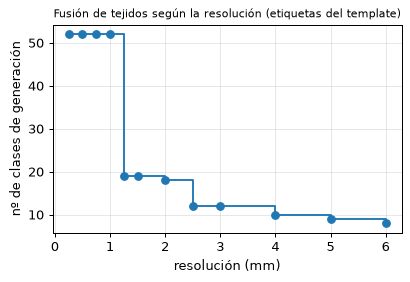

ejemplos de grupos a 3 mm:
  background             <- [0]
  cerebral_wm            <- [2, 25, 41, 57, 85]
  cortex                 <- [3, 42, 1001, 1002, 1003, 1005, 1006, 1007, 1008, 1009, 1010, 1011] ...
  lateral_ventricles     <- [4, 43]
  csf_spaces             <- [5, 14, 15, 24, 44, 72]
  cerebellar_wm          <- [7, 46]
  cerebellar_cortex      <- [8, 47]
  thalamus               <- [10, 49]


In [10]:
present = set(np.unique(seg_raw).tolist())
resolutions = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0]
n_groups = []
for res in resolutions:
    groups = tree.label_groups(res)
    n_groups.append(sum(1 for labs in groups.values() if present & set(labs)))

plt.figure(figsize=(5, 3))
plt.step(resolutions, n_groups, where='post', marker='o')
plt.xlabel('resolución (mm)')
plt.ylabel('nº de clases de generación')
plt.title('Fusión de tejidos según la resolución (etiquetas del template)', fontsize=9)
plt.grid(alpha=0.3)
plt.show()

g3 = tree.label_groups(3.0)
print('ejemplos de grupos a 3 mm:')
for k in list(g3)[:8]:
    print(f'  {k:22s} <- {g3[k][:12]}{" ..." if len(g3[k]) > 12 else ""}')

> **Nota sobre `contrast`.** `r_max` puede ser un diccionario por contraste (`{"default": 1.0, "FLAIR": 2.0}`), por ejemplo si una estructura se ve en T2 pero no en T1. En este árbol no hay ningún `r_max` por contraste, así que el contraste sorteado no cambia las fusiones (sólo se transmite en `info`).

## 3. Superresolución de etiquetas (offline)

### 3.1 Por qué

La segmentación de entrada está a **1 mm**, pero las deformaciones y el volumen parcial necesitan una rejilla mucho más fina (0.25 mm). Si simplemente replicamos cada vóxel (interpolación *nearest*), los bordes quedan como **escaleras** de 1 mm: al deformar y al calcular el volumen parcial, la red vería artefactos de bloque que no existen en las imágenes reales.

La solución: tratar cada etiqueta como una **función indicadora** suave, interpolarla y volver a decidir la etiqueta:

1. **one-hot**: para cada etiqueta `v`, un volumen binario `1[seg == v]`;
2. **upsampling con sinc**: interpolación limitada en banda, que se hace en el dominio de Fourier rellenando el espectro con ceros (*zero padding*);
3. **suavizado gaussiano** (σ = 0.5 mm), aplicado en Fourier (multiplicar por la transformada de la gaussiana); quita el *ringing* (fenómeno de Gibbs) del sinc y redondea las esquinas;
4. **argmax**: cada vóxel HR se queda con la etiqueta cuya indicadora suavizada es mayor.

### 3.2 Ejemplo 1D: sinc, Gibbs y suavizado

Una indicadora 1D (un "tejido" de 6 vóxeles) superresuelta ×4, con y sin suavizado:

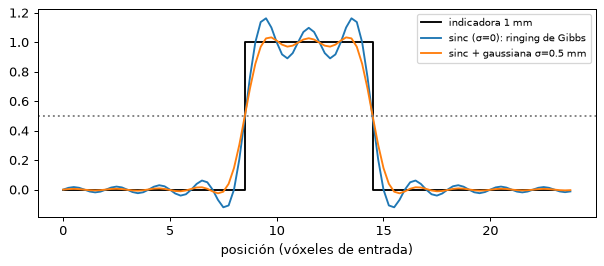

In [11]:
x = torch.zeros(24)
x[9:15] = 1
up = 4
y_sinc = tg._sinc_upsample_smooth(x, up, sigma_mm=0, out_voxel_mm=1 / up)
y_smooth = tg._sinc_upsample_smooth(x, up, sigma_mm=0.5, out_voxel_mm=1 / up)
pos_lr = np.arange(24)
pos_hr = np.arange(24 * up) / up       # el vóxel HR j está en la coordenada j/up de la entrada

plt.figure(figsize=(8, 3))
plt.step(pos_lr, x, where='mid', color='k', label='indicadora 1 mm')
plt.plot(pos_hr, y_sinc, label='sinc (σ=0): ringing de Gibbs')
plt.plot(pos_hr, y_smooth, label='sinc + gaussiana σ=0.5 mm')
plt.axhline(0.5, ls=':', color='gray')
plt.xlabel('posición (vóxeles de entrada)')
plt.legend(fontsize=8)
plt.show()

Las oscilaciones del sinc puro (Gibbs) pueden crear "islas" de etiqueta lejos del borde; con el suavizado desaparecen. El borde (donde la curva cruza 0.5) sigue en el mismo sitio.

### 3.3 Ejemplo 3D de juguete

Hacemos una versión 3D a 1 mm del mapa de juguete (cilindros), la superresolvemos ×4 con `super_resolve_labels` y la comparamos con la replicación *nearest*:

1 mm: (42, 42, 9)  -> 0.25 mm: (168, 168, 36)


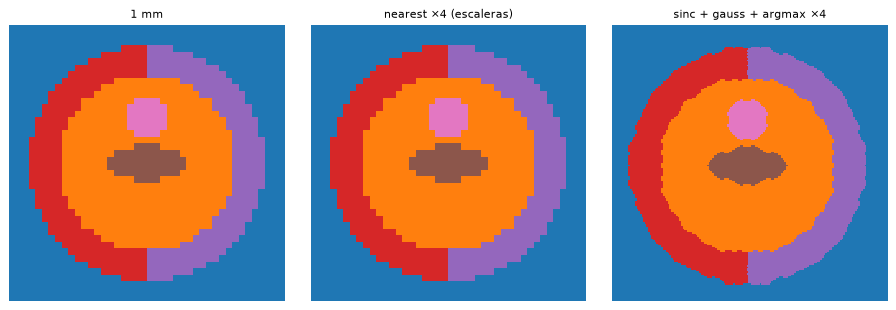

In [12]:
def toy_volume(n=42, nz=9, vox=1.0):
    """Mapa de juguete 3D (geometría en mm), mismo diseño que toy2d."""
    c = n * vox / 2
    p = (np.arange(n) + 0.5) * vox
    X, Y = np.meshgrid(p, p, indexing='ij')
    r = np.hypot(X - c, Y - c)
    sl = np.zeros((n, n), int)
    sl[r < 18] = np.where(X[r < 18] < c, 3, 4)
    sl[r < 13.5] = 1
    sl[((X - c) / 6) ** 2 + ((Y - c) / 2.6) ** 2 < 1] = 5
    sl[np.hypot(X - c, Y - c - 7) < 3.2] = 6
    return np.repeat(sl[:, :, None], nz, axis=2)

toy_1mm = torch.as_tensor(toy_volume())
toy_hr = tg.super_resolve_labels(toy_1mm, factor=4, voxel_mm=1, sigma_mm=0.5)
toy_nn = toy_1mm.repeat_interleave(4, 0).repeat_interleave(4, 1).repeat_interleave(4, 2)
print('1 mm:', tuple(toy_1mm.shape), ' -> 0.25 mm:', tuple(toy_hr.shape))

row([mid(toy_1mm), mid(toy_nn), mid(toy_hr)],
    ['1 mm', 'nearest ×4 (escaleras)', 'sinc + gauss + argmax ×4'],
    'tab10', size=3.4, vmin=0, vmax=9)

**Detalles de implementación** (`super_resolve_labels`):
- Cada etiqueta se procesa sólo dentro de su ***bounding box*** (+ un margen mayor que el soporte del suavizado). Una parcela pequeña cuesta poco, aunque haya ~100 etiquetas.
- El canal del **fondo nunca se calcula**: la interpolación y el suavizado son lineales y las indicadoras suman 1 en cada vóxel, así que la indicadora suavizada del fondo es exactamente `1 − Σ(otras)`. Al final, un vóxel es fondo si `1 − total > mejor`.
- Se guardan sólo tres volúmenes HR (`best`, `total`, `out`), no uno por etiqueta.

`prepare_template` añade además: (a) etiquetas fuera del árbol → fondo (`restrict_labels`), (b) recorte alrededor del cerebro con 16 mm de margen, (c) ajuste del tamaño para que la forma HR sea múltiplo de `factor` = 3 (para que el volumen parcial caiga exactamente en la rejilla de 0.75 mm) y (d) la affine HR: `affine_hr = affine · diag(1/up, 1/up, 1/up, 1)`, ya que el vóxel HR `j` está en la coordenada `j/up` de la entrada.


<div class="alert alert-warning">
<strong>Warning:</strong> El HR es un múltiplo de 3. No sé si servirá para 0.33.
</div>

### 3.4 El template real

Es la operación más cara, por eso se hace **una vez** y se guarda en caché (`data/outputs/templates/seg_hr0.25mm.nii.gz`). `build_templates` lo carga si ya existe.

template HR: (720, 888, 780) = 499 M vóxeles, vóxel 0.25 mm


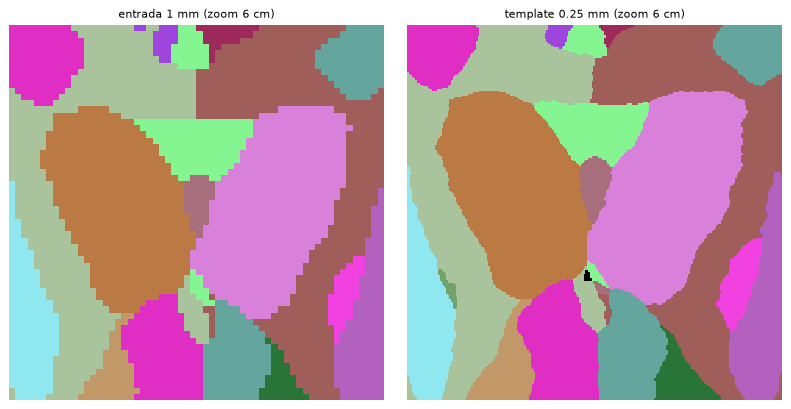

In [13]:
templates = tg.build_templates([SEG], TREE, cfg, CACHE, DEVICE)
lab_hr, aff_hr = templates[0]
print(f'template HR: {tuple(lab_hr.shape)} = {lab_hr.numel() / 1e6:.0f} M vóxeles, '
      f'vóxel {aff_hr[0, 0]:g} mm')

# zoom en la misma zona del mundo a 1 mm y a 0.25 mm
sl_1mm = axial(seg_raw, seg.affine, point)
sl_hr = axial(lab_hr, aff_hr, point)
c1 = np.array(sl_1mm.shape) // 2
ch = np.array(sl_hr.shape) // 2
w = 30   # mm
cmap = random_label_cmap(3000)
row([sl_1mm[c1[0] - w:c1[0] + w, c1[1] - w:c1[1] + w] % 3000,
     sl_hr[ch[0] - 4 * w:ch[0] + 4 * w, ch[1] - 4 * w:ch[1] + 4 * w] % 3000],
    ['entrada 1 mm (zoom 6 cm)', 'template 0.25 mm (zoom 6 cm)'], cmap, size=4.5,
    vmin=0, vmax=2999)

## 4. El generador: espacio de etiquetas

`TreeGenerator(templates, tree, cfg)` prepara todo lo que no cambia entre muestras:

1. **Espacio de etiquetas.** Las etiquetas crudas (0, 2, 3, …, 2035) se renumeran a **índices contiguos** `0..K-1`: el índice 0 es el fondo y `gen.labels[i]` es el valor crudo del índice `i`. Con `output_labels='templates'` son las etiquetas presentes en los templates (y en el árbol); con `'tree'`, todas las del árbol. El template se convierte a índices con una tabla de consulta (LUT) y se guarda como `uint8` (si K ≤ 256), 4 veces menos memoria que `int32`.
2. **Modelo de intensidades** (`TreeSampling`) con `std_noise=0` (el ruido de adquisición se añade al final).
3. **Reglas de morfología** resueltas a conjuntos de índices (sección 5).
4. Transformaciones de **cornucopia**: deformación, campo de sesgo, ruido, min-max.

<div class="alert alert-warning">
<strong>Warning:</strong> La funcion conviertea UINT8 lo cual no servira para 333 etiquetas
</div>

In [14]:
gen = tg.TreeGenerator(templates, TREE, cfg, device=DEVICE)
names = gen.label_names()
print(f'K = {gen.nb_labels} etiquetas (índices 0..{gen.nb_labels - 1})')
for i in [0, 1, 2, 3, 10, 40, gen.nb_labels - 1]:
    print(f'  índice {i:3d} -> valor crudo {gen.labels[i]:5d}  ({names[i]})')
lab = gen.templates[0][0]
print('template en índices:', lab.dtype, tuple(lab.shape), lab.device)

K = 99 etiquetas (índices 0..98)
  índice   0 -> valor crudo     0  (background)
  índice   1 -> valor crudo     2  (cerebral_wm_2)
  índice   2 -> valor crudo     4  (lateral_ventricles_4)
  índice   3 -> valor crudo     5  (inf_lat_ventricles_5)
  índice  10 -> valor crudo    14  (third_ventricle)
  índice  40 -> valor crudo  1011  (cortex_1011_2011_1011)
  índice  98 -> valor crudo  2035  (cortex_1035_2035_2035)
template en índices: torch.uint8 (720, 888, 780) cuda:3


## 5. Erosión / dilatación aleatoria (paso 3)

### 5.1 Concepto

Para que la red no memorice el grosor exacto de cada estructura del template, cambiamos las formas: en cada pareja `(a, b)` de `morpho_pairs`, con probabilidad `morpho_prob` (0.5), uno de los dos grupos (al azar) **crece** dentro del otro durante `n ~ U{1..4}` iteraciones de 0.25 mm (hasta 1 mm). Es una dilatación **restringida**: el grupo que crece sólo invade vóxeles del grupo que encoge, nunca otros tejidos.

Las parejas se escriben **en términos del árbol**: `["cerebral_wm", "cortex"]` significa todas las etiquetas del subárbol `cortex` (la corteza y sus 34 parcelas). Por eso funciona con cualquier conjunto de etiquetas.

**El truco del max-pooling.** Si el grupo que crece tiene varias etiquetas (p. ej. las parcelas corticales), cada vóxel nuevo debe copiar la etiqueta **de un vecino**. Se hace así:
- `val = índice + 1` en los vóxeles del grupo que crece, `0` en el resto;
- `nbr = max_pool3d(val, 3×3×3)`: en cada vóxel, el mayor valor de sus 26 vecinos → `nbr > 0` indica "tengo un vecino del grupo que crece", y `nbr − 1` es la etiqueta de ese vecino;
- los vóxeles del grupo que encoge con `nbr > 0` toman la etiqueta `nbr − 1`.

Ejemplo numérico mínimo (un corte 2D, z = 1): las etiquetas 1 y 2 crecen dentro de la 5:

In [15]:
sub = torch.tensor([[5, 5, 5, 5, 5, 5],
                    [5, 5, 5, 5, 5, 5],
                    [1, 1, 1, 2, 2, 2],
                    [1, 1, 1, 2, 2, 2]])[..., None]          # (X, Y, 1)
grow, shrink = torch.tensor([1, 2]), torch.tensor([5])
for it in range(2):
    val = torch.where(torch.isin(sub, grow), sub.float() + 1, 0.)
    nbr = F.max_pool3d(val[None, None], 3, stride=1, padding=1)[0, 0]
    take = torch.isin(sub, shrink) & (nbr > 0)
    sub = torch.where(take, (nbr - 1).long(), sub)
    print(f'iteración {it + 1}:\n{sub[..., 0].numpy()}')

iteración 1:
[[5 5 5 5 5 5]
 [1 1 2 2 2 2]
 [1 1 1 2 2 2]
 [1 1 1 2 2 2]]
iteración 2:
[[1 2 2 2 2 2]
 [1 1 2 2 2 2]
 [1 1 1 2 2 2]
 [1 1 1 2 2 2]]


Cada iteración avanza una capa de vóxeles, y cada vóxel nuevo copia una etiqueta vecina (en los empates, la de mayor índice). Para ahorrar memoria, en el código real todo esto se hace sólo dentro de la *bounding box* de la pareja.

### 5.2 Ejemplo de juguete con el generador

Creamos un generador pequeño sobre el template de juguete (el que superresolvimos en 3.3, recortado a una forma múltiplo de 3) con una sola regla `wm ↔ gm`, siempre activa y con 6 iteraciones (1.5 mm) para que se vea bien:

etiquetas del generador de juguete: [0, 1, 3, 4, 5, 6]  parejas: [('wm', 'gm', [1], [2, 3])]


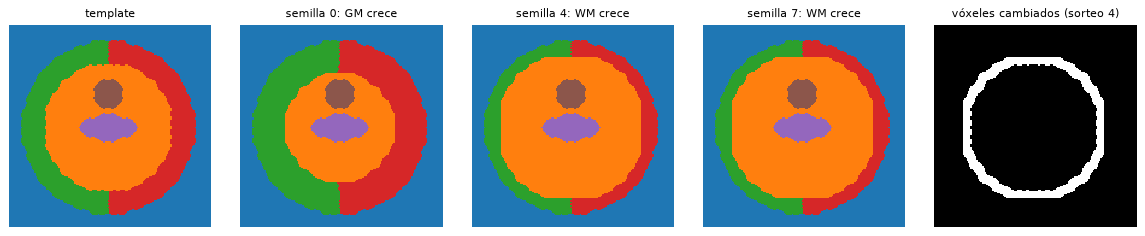

In [16]:
toy_template = toy_hr[:, :, :33]                 # 168 × 168 × 33 a 0.25 mm (múltiplo de 3)
toy_aff = np.diag([0.25, 0.25, 0.25, 1.])
toy_cfg = tg.TreeGeneratorConfig(
    morpho_pairs=(('wm', 'gm'),), morpho_prob=1.0, morpho_iter=(6, 6),
    elastic_dmax_mm=3.0, rotations=10., zooms=0.1, motion_prob=0.)
toy_gen = tg.TreeGenerator([(toy_template, toy_aff)], toy_tree, toy_cfg)
toy_lab = toy_gen.templates[0][0]
print('etiquetas del generador de juguete:', toy_gen.labels.tolist(),
      ' parejas:', [(a, b, ia, ib) for a, b, ia, ib in toy_gen.morpho_pairs])

imgs, titles = [mid(toy_lab)], ['template']
for k in (0, 4, 7):      # semillas elegidas para ver las dos direcciones
    random.seed(k)
    lab_k = toy_gen._morphology(toy_lab.clone())
    changed = (lab_k != toy_lab)
    grew = 'WM crece' if (lab_k[changed] == toy_gen.index[1]).all() else 'GM crece'
    imgs += [mid(lab_k)]
    titles += [f'semilla {k}: {grew}']
diff = (imgs[2] != imgs[0]).astype(float)
row(imgs + [diff], titles + ['vóxeles cambiados (sorteo 4)'],
    ['tab10'] * 4 + ['gray'], size=2.6, vmin=0, vmax=9)

Con la semilla 4 la WM crece y la corteza adelgaza; con las otras, al revés. Cuando la GM crece hacia la WM, cada vóxel nuevo copia la etiqueta de su vecino de corteza, así que la frontera entre `gm_a` (3) y `gm_b` (4) se mantiene.

### 5.3 El paso real

Con 11 parejas activas cada una con probabilidad 0.5. Mostramos los vóxeles que cambian:

<div class="alert alert-warning">
<strong>Warning:</strong> Cuidado con esta transfomrcacion porque puede causar morfologias imposibles, por ejemplo el WM podria llegar a tocar el CSF.
</div>

vóxeles cambiados: 17.15 M (3.44 % del volumen)


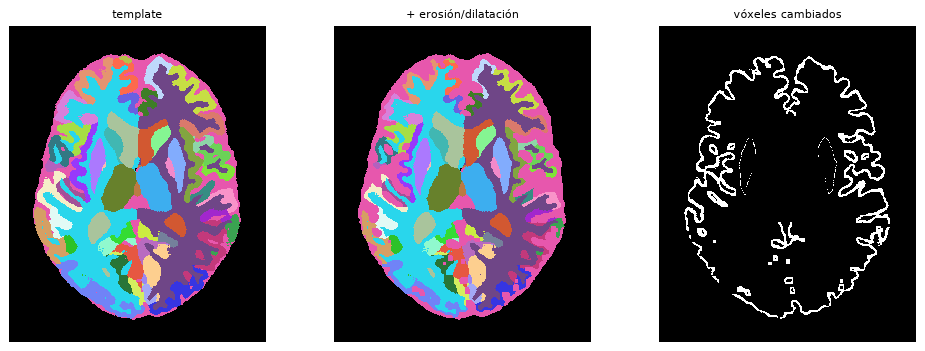

In [17]:
tg.seed_everything(20)
with torch.no_grad():
    lab_m = gen._morphology(lab.clone())
changed = (lab_m != lab)
print(f'vóxeles cambiados: {changed.sum().item() / 1e6:.2f} M '
      f'({100 * changed.float().mean().item():.2f} % del volumen)')
lkw = dict(cmap=random_label_cmap(gen.nb_labels), vmin=0, vmax=gen.nb_labels - 1)
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
show(axes[0], axial(lab.cpu(), aff_hr, point), 'template', **lkw)
show(axes[1], axial(lab_m.cpu(), aff_hr, point), '+ erosión/dilatación', **lkw)
show(axes[2], axial(changed.cpu(), aff_hr, point), 'vóxeles cambiados')
fig.tight_layout()
plt.show()

## 6. Deformación afín + elástica (paso 4)

### 6.1 Concepto

Para multiplicar la variedad anatómica aplicamos una transformación espacial aleatoria:
- **afín**: rotaciones `U(−10°, 10°)` por eje, zoom `U(−0.1, 0.1)` alrededor de 1 (cizalla y traslación desactivadas);
- **elástica**: desplazamientos aleatorios en una rejilla de control de 7×7×7 puntos (`elastic_ctrl`), de hasta 7.5 mm (`elastic_dmax_mm`), interpolados de forma suave a todo el volumen.

La transformación se representa como un **campo de muestreo** (*flow*): para cada vóxel de la imagen de salida, la coordenada del template de la que se lee su valor (*pull* / *backward warping*). Así cada vóxel de salida tiene exactamente un valor.

**Interpolación de etiquetas: siempre *nearest*.** Con interpolación lineal, un punto entre la etiqueta 2 (WM izq.) y la 41 (WM der.) recibiría 21.5 → la etiqueta 21 o 22, que no tienen nada que ver. Las etiquetas son categorías, no números: se copia la del vóxel más cercano. Como el template está a 0.25 mm, el error de *nearest* es como mucho 0.125 mm, invisible a 0.75 mm.

**El truco de memoria.** Un campo a 0.25 mm serían 3 × 500 M floats = 6 GB. Pero el campo es suave, así que se sortea en la rejilla de **0.75 mm** (27 veces menos puntos), y se interpola trilinealmente a 0.25 mm **por bloques** (*slabs*) de 16 cortes justo antes de usarlo. Las coordenadas se convierten de la rejilla LR a la HR con `x_HR = f · x_LR + (f − 1)/2`, porque el centro del vóxel LR `i` coincide con el del vóxel HR `f·i + (f−1)/2` (el del medio de sus 3 vóxeles HR).

### 6.2 Ejemplo de juguete: el campo

Sorteamos un campo en la rejilla LR del juguete y lo aplicamos a una cuadrícula para verlo:

flow: (1, 56, 56, 11, 3)  desplazamiento máx: 6.99 mm


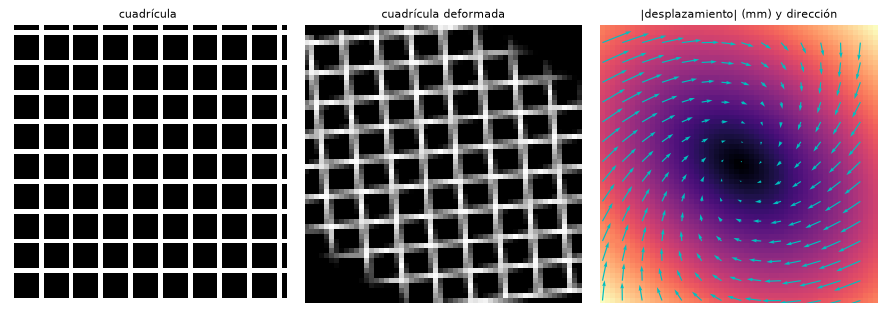

In [18]:
X, Y, Z = (s // 3 for s in toy_lab.shape)                 # rejilla LR (0.75 mm)
torch.manual_seed(1)
random.seed(1)
flow = toy_gen.deform(torch.zeros([1, X, Y, Z]))        # (1, X, Y, Z, 3) coordenadas absolutas
ident = torch.stack(torch.meshgrid(*[torch.arange(s, dtype=torch.float) for s in (X, Y, Z)],
                                   indexing='ij'), -1)
disp = (flow[0] - ident) * 0.75                          # desplazamiento en mm
print('flow:', tuple(flow.shape), f' desplazamiento máx: {disp.norm(dim=-1).max():.2f} mm')

grid = torch.zeros([1, 1, X, Y, Z])
grid[:, :, ::6] = 1
grid[:, :, :, ::6] = 1
warped = warps.apply_flow(grid, flow, has_identity=True, mode='bilinear')

z = Z // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(grid[0, 0, :, :, z].T, cmap='gray', origin='lower')
axes[0].set_title('cuadrícula', fontsize=9)
axes[1].imshow(warped[0, 0, :, :, z].T, cmap='gray', origin='lower')
axes[1].set_title('cuadrícula deformada', fontsize=9)
d = disp[:, :, z]
s = 4
axes[2].imshow(d.norm(dim=-1).T, cmap='magma', origin='lower')
axes[2].quiver(np.arange(0, X, s), np.arange(0, Y, s), d[::s, ::s, 0].T, d[::s, ::s, 1].T,
               color='c', scale=40)
axes[2].set_title('|desplazamiento| (mm) y dirección', fontsize=9)
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()

### 6.3 Ejemplo de juguete: etiquetas deformadas

`_deform` hace todo: sortea el campo LR, lo sube a HR por bloques y remuestrea las etiquetas HR con *nearest*. Tres sorteos:

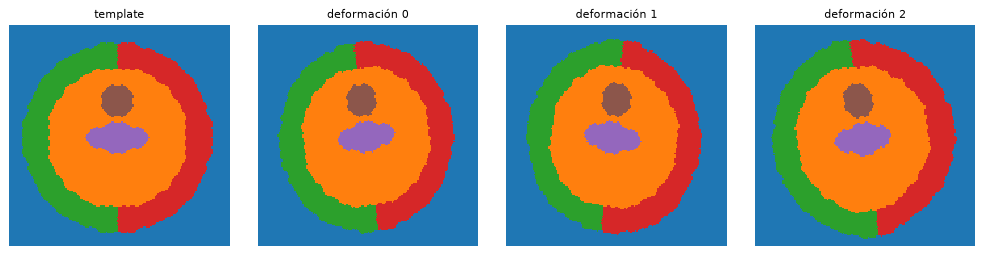

In [19]:
imgs, titles = [mid(toy_lab)], ['template']
for k in range(3):
    torch.manual_seed(10 + k)
    imgs.append(mid(toy_gen._deform(toy_lab)))
    titles.append(f'deformación {k}')
row(imgs, titles, 'tab10', size=2.8, vmin=0, vmax=9)

### 6.4 El paso real

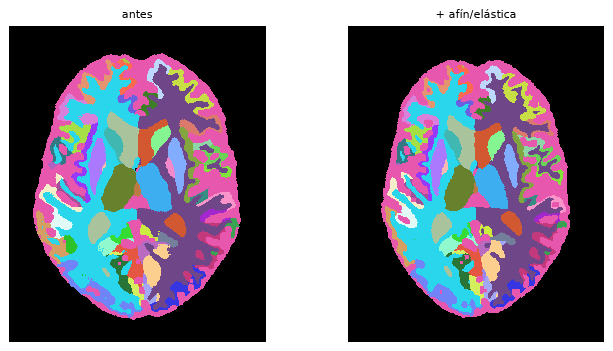

In [20]:
torch.manual_seed(0)
with torch.no_grad():
    lab_d = gen._deform(lab_m)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
show(axes[0], axial(lab_m.cpu(), aff_hr, point), 'antes', **lkw)
show(axes[1], axial(lab_d.cpu(), aff_hr, point), '+ afín/elástica', **lkw)
fig.tight_layout()
plt.show()

## 7. Volumen parcial (paso 5)

### 7.1 Concepto

En una resonancia real, un vóxel de 0.75 mm en el borde entre WM y GM contiene **una mezcla** de los dos tejidos, y su intensidad es la media ponderada: es el **efecto de volumen parcial**. Es la razón por la que los bordes reales no son escalones perfectos.

Lo simulamos con la rejilla HR: cada vóxel LR contiene 3×3×3 = 27 vóxeles HR, así que la fracción de cada etiqueta dentro del vóxel LR es

$$pv_k(\text{vóxel}) = \frac{\#\{\text{vóxeles HR del bloque con etiqueta } k\}}{27}$$

y la **segmentación de salida** es la etiqueta con mayor fracción (la mayoritaria).

**Implementación sin one-hot.** Con K = 99 etiquetas, un one-hot a 0.25 mm serían 99 × 500 M floats (200 GB). En su lugar, cada bloque de 27 vóxeles se convierte en una fila y se hace un **histograma** con `scatter_add_` → tabla `(nº de vóxeles LR, K)`, procesando el volumen por bloques de cortes (*slabs*) de ~256 MB.

Ejemplo con un solo vóxel LR:

In [21]:
blk = torch.tensor([1] * 14 + [3] * 9 + [5] * 4)        # 27 vóxeles HR de un vóxel LR
p = torch.zeros(1, 7)
p.scatter_add_(1, blk[None], torch.ones(1, 27))
p /= 27
print('fracciones por etiqueta:', np.round(p[0].numpy(), 3).tolist())
print('etiqueta de salida (argmax):', p.argmax(1).item())

fracciones por etiqueta: [0.0, 0.5189999938011169, 0.0, 0.3330000042915344, 0.0, 0.14800000190734863, 0.0]
etiqueta de salida (argmax): 1


### 7.2 Ejemplo de juguete

Las fracciones se agrupan por **clase de generación** `g` (etiquetas fusionadas, sección 8): `pv_g = Σ_{k∈g} pv_k`. Aquí, a 0.75 mm, cada etiqueta es su propia clase:

clases: ['background', 'wm', 'gm_a', 'gm_b', 'csf', 'deep_gm']  pv: (6, 56, 56, 11)  seg: (56, 56, 11)
suma de pv en cada vóxel = 1: True


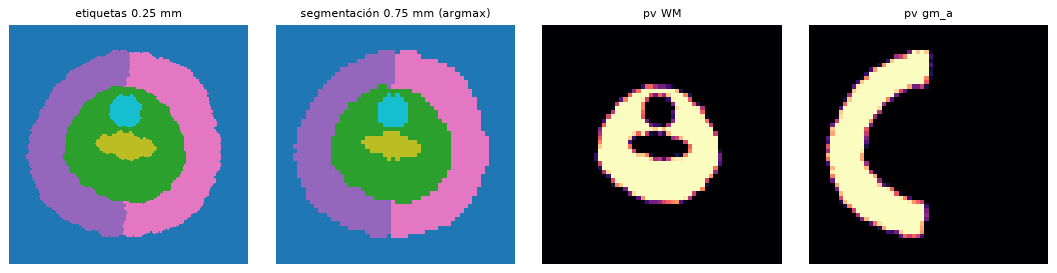

In [22]:
torch.manual_seed(0)
toy_d = toy_gen._deform(toy_gen._morphology(toy_lab.clone()))
mus_t, sig_t = toy_gen.scheme.compute_stats(C, V, 0.75)
grp_t, names_t = toy_gen.scheme.label_set_lut(0.75)
img_t, seg_t, pv_t = toy_gen._synthesize(toy_d, mus_t, sig_t, grp_t, return_pv=True)
print('clases:', names_t, ' pv:', tuple(pv_t.shape), ' seg:', tuple(seg_t.shape))
print('suma de pv en cada vóxel = 1:', torch.allclose(pv_t.sum(0), torch.ones(1)))
row([mid(toy_d), mid(seg_t), mid(pv_t[names_t.index('wm')]), mid(pv_t[names_t.index('gm_a')])],
    ['etiquetas 0.25 mm', 'segmentación 0.75 mm (argmax)', 'pv WM', 'pv gm_a'],
    ['tab10', 'tab10', 'magma', 'magma'], size=3)

Los mapas de volumen parcial valen 1 dentro del tejido, 0 fuera, y valores intermedios en una franja de un vóxel en el borde.

### 7.3 El paso real

`_synthesize` calcula a la vez el volumen parcial, la segmentación y la imagen (sección 8). Para la WM izquierda:

affine LR (el vóxel LR i está centrado en el HR f·i + (f-1)/2):
 [[   0.75    0.      0.    -89.75]
 [   0.      0.75    0.   -125.75]
 [   0.      0.      0.75  -87.75]
 [   0.      0.      0.      1.  ]]


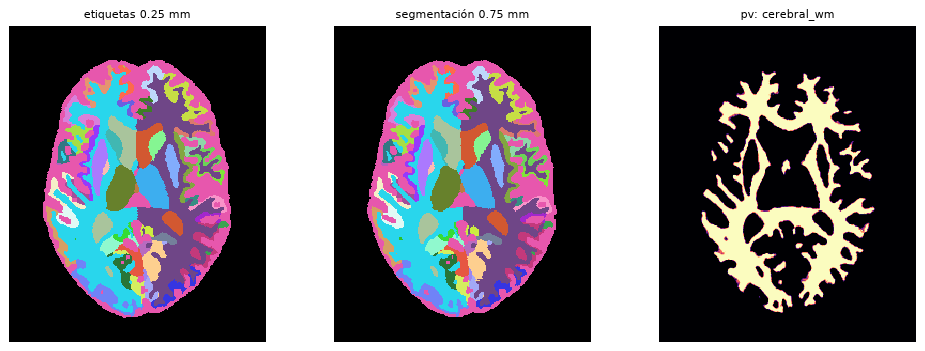

In [23]:
tg.seed_everything(0)
C_r, V_r, res_r, contrast_r = gen._sample_contrast()
mus_r, sig_r = gen.scheme.compute_stats(C_r, V_r, res_r, contrast_r)
grp_r, names_r = gen.scheme.label_set_lut(res_r, contrast_r)
with torch.no_grad():
    img_tree, seg_lr, pv = gen._synthesize(lab_d, mus_r, sig_r, grp_r, return_pv=True)
f = cfg.factor
aff_lr = aff_hr @ np.array([[f, 0, 0, (f - 1) / 2], [0, f, 0, (f - 1) / 2],
                            [0, 0, f, (f - 1) / 2], [0, 0, 0, 1]])
print('affine LR (el vóxel LR i está centrado en el HR f·i + (f-1)/2):\n', np.round(aff_lr, 2))
wm = grp_r[gen.index[2]]
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
show(axes[0], axial(lab_d.cpu(), aff_hr, point), 'etiquetas 0.25 mm', **lkw)
show(axes[1], axial(seg_lr.cpu(), aff_lr, point), 'segmentación 0.75 mm', **lkw)
show(axes[2], axial(pv[wm].cpu(), aff_lr, point), f'pv: {names_r[wm]}', cmap='magma')
fig.tight_layout()
plt.show()

## 8. Intensidades del árbol y fusión de tejidos (paso 6)

### 8.1 Concepto

Por cada imagen se sortea:
- `C`, `V`: colores principales (`colors_mu = (0, 255)`, `colors_sigma = (0.255, 2.55)`, los rangos del artículo × 255),
- la resolución `res` que decide las fusiones (`cfg.resolution`; si es `None`, `target_voxel` = 0.75 mm; puede ser un rango `[lo, hi]`),
- un contraste de `cfg.contrasts`.

`compute_stats` da `(μ_k, σ_k)` por etiqueta y `label_set_lut` da la **clase de generación** de cada etiqueta (`group_of`). La imagen es una **mezcla por volumen parcial**:

$$I(x) = \sum_g pv_g(x)\,\big(\mu_g + \sigma_g\,\varepsilon_g(x)\big), \qquad \varepsilon_g(x) \sim \mathcal N(0,1)$$

- Cada clase tiene **una sola** gaussiana; las etiquetas fusionadas son indistinguibles en la imagen.
- El ruido `ε` es independiente por vóxel y por clase: textura dentro del tejido.
- En un borde, la intensidad es la media de los tejidos ponderada por sus fracciones.
- Luego la imagen se divide por `intensity_scale = 255`, para que los rangos de los artefactos del artículo (pensados para [0, 1]) sigan valiendo.

### 8.2 Ejemplo de juguete: 0.75 mm frente a 2 mm

Las mismas etiquetas deformadas y los mismos colores principales, cambiando sólo la resolución de fusión:

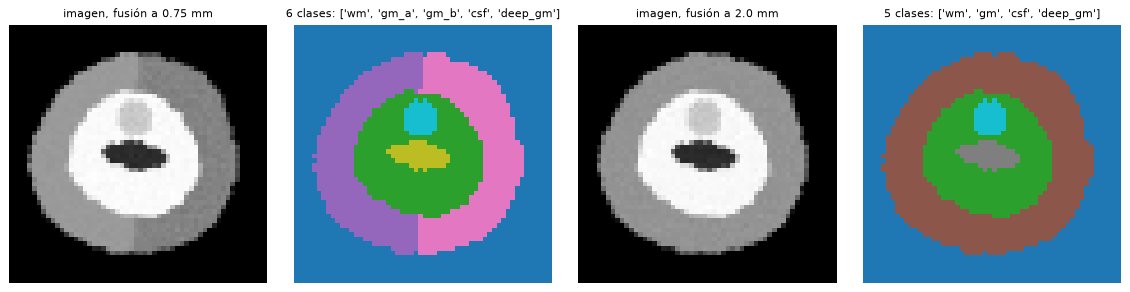

In [24]:
imgs, titles = [], []
for res in (0.75, 2.0):
    s = TreeSampling(toy_gen.labels, toy_tree, std_noise=0., seed=5, verbose=False)
    mus_t, sig_t = s.compute_stats(C, V, res)
    grp_t, names_t = s.label_set_lut(res)
    img_t, seg_t, _ = toy_gen._synthesize(toy_d, mus_t, sig_t, grp_t)
    imgs += [mid(img_t[0]), mid(grp_t[seg_t.long().numpy()])]
    titles += [f'imagen, fusión a {res} mm', f'{len(names_t)} clases: {names_t[1:]}']
row(imgs, titles, ['gray', 'tab10', 'gray', 'tab10'], size=3.2)

A 0.75 mm las dos mitades de la corteza (`gm_a`, `gm_b`) tienen intensidades distintas; a 2 mm son una sola clase `gm` con la misma gaussiana.

### 8.3 El paso real: varias resoluciones

Mismas etiquetas deformadas `lab_d` y mismos colores principales; sólo cambia la resolución de fusión. Abajo, la segmentación coloreada por **clase de generación** (lo que la red puede distinguir en esa imagen):

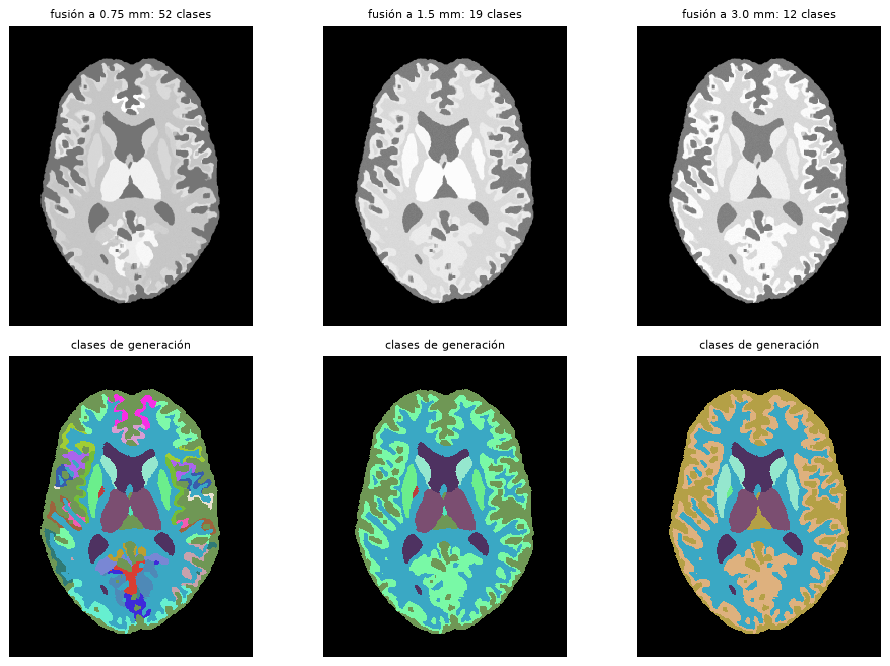

contraste sorteado: FLAIR  C = [215.3 193.3 107.2]  V = [0.85 1.43 1.18]


In [25]:
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
for j, res in enumerate([0.75, 1.5, 3.0]):
    mus_j, sig_j = gen.scheme.compute_stats(C_r, V_r, res, contrast_r)
    grp_j, names_j = gen.scheme.label_set_lut(res, contrast_r)
    with torch.no_grad():
        img_j, seg_j, _ = gen._synthesize(lab_d, mus_j, sig_j, grp_j)
    G = len(names_j)
    show(axes[0, j], axial(img_j[0].cpu(), aff_lr, point), f'fusión a {res} mm: {G} clases')
    show(axes[1, j], axial(grp_j[seg_j.cpu().long().numpy()], aff_lr, point), 'clases de generación',
         cmap=random_label_cmap(G, seed=2), vmin=0, vmax=G - 1)
fig.tight_layout()
plt.show()
print('contraste sorteado:', contrast_r, ' C =', np.round(C_r, 1), ' V =', np.round(V_r, 2))

> **Importante.** `res` sólo decide **qué tejidos se fusionan**. La imagen se sigue generando en la rejilla de 0.75 mm, sin desenfocar ni submuestrear. Para imitar de verdad una adquisición de 3 mm haría falta añadir un paso de desenfoque + submuestreo (como en SynthSeg).

## 9. Artefactos (paso 7)

Partimos de la imagen del árbol `img_tree` (sección 7.3), dividida por `intensity_scale`.

### 9.1 Campo de sesgo (*bias field*)

La inhomogeneidad de la bobina hace que la misma estructura sea más clara en una zona que en otra. Se modela como un **campo multiplicativo suave**: valores aleatorios en una rejilla de 5×5×5 puntos (`bias_ctrl`) en `(1 − 0.5, 1 + 0.5)` (`bias_vmax`), interpolados de forma suave a todo el volumen. Se aplica con probabilidad `bias_prob` = 1.

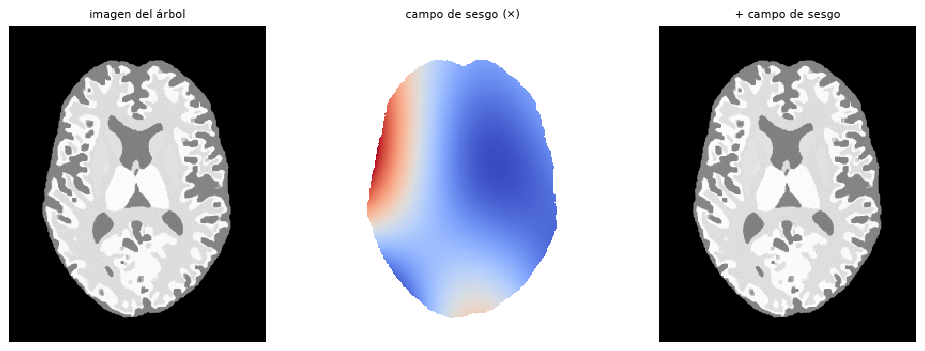

In [26]:
torch.manual_seed(0)
img0 = img_tree / cfg.intensity_scale
with torch.no_grad():
    img_bias = gen.bias(img0)
field = (img_bias / img0.clamp_min(1e-6))[0]
field[img0[0] < 1e-3] = float('nan')          # fuera del cerebro el cociente no tiene sentido
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
show(axes[0], axial(img0[0].cpu(), aff_lr, point), 'imagen del árbol')
show(axes[1], axial(field.cpu(), aff_lr, point), 'campo de sesgo (×)', cmap='coolwarm')
show(axes[2], axial(img_bias[0].cpu(), aff_lr, point), '+ campo de sesgo')
fig.tight_layout()
plt.show()

### 9.2 Movimiento durante la adquisición

**k-espacio.** La resonancia no mide la imagen directamente sino su **transformada de Fourier** (el k-espacio), línea a línea. El **centro** del k-espacio (bajas frecuencias) contiene el contraste y la posición global de la anatomía; la **periferia** (altas frecuencias), los bordes y detalles.

**Disparos (*shots*).** En una adquisición 3D, las líneas a lo largo de la dirección de codificación de fase se adquieren en varios disparos. Si el paciente se mueve entre disparos, cada bloque de líneas corresponde a la cabeza en una posición distinta. Al reconstruir (FFT inversa), esas incoherencias se convierten en **ghosting** (copias desplazadas) y emborronamiento.

`cc.IntraScanMotionTransform` lo simula: para cada disparo aplica una transformación rígida aleatoria a la imagen (hasta 10° y 10 mm), calcula su FFT a lo largo del eje elegido y se queda con las líneas de ese disparo. Patrón **secuencial** con 3 disparos: el disparo 0 llena el primer tercio de k, el 1 el tercio central y el 2 el último.

Veamos el k-espacio de un corte y el patrón de disparos:

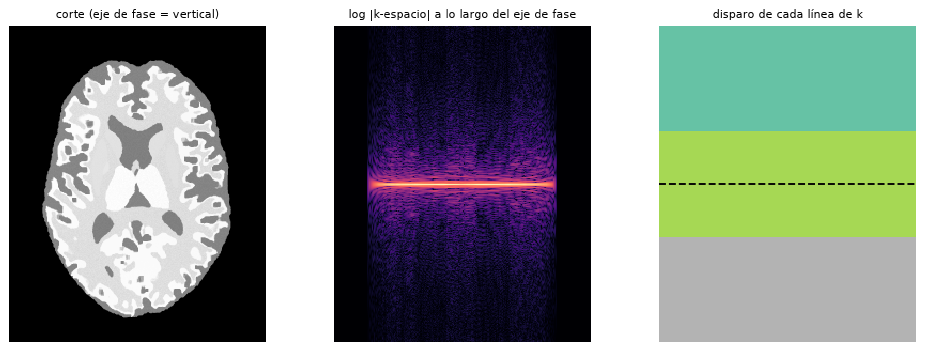

la línea central (k = 0, índice 148) la adquiere el disparo 1


In [27]:
sl = axial(img_bias[0].cpu(), aff_lr, point)
k = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(sl, axes=0), axis=0), axes=0)
nk = sl.shape[0]
length = math.ceil(nk / cfg.motion_shots)
shot_of_line = np.minimum(np.arange(nk) // length, cfg.motion_shots - 1)
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
show(axes[0], sl, 'corte (eje de fase = vertical)')
show(axes[1], np.log1p(np.abs(k)), 'log |k-espacio| a lo largo del eje de fase', cmap='magma')
show(axes[2], np.repeat(shot_of_line[:, None], sl.shape[1], 1), 'disparo de cada línea de k',
     cmap='Set2')
axes[2].axhline(nk // 2, color='k', ls='--')
fig.tight_layout()
plt.show()
print(f'la línea central (k = 0, índice {nk // 2}) la adquiere el disparo {shot_of_line[nk // 2]}')

**El disparo central decide la posición global.** Como el centro del k-espacio lo adquiere el disparo 1, la imagen reconstruida aparece, en bloque, en la **posición de ese disparo**. Si los tres disparos se mueven, la imagen entera queda girada/desplazada respecto a la segmentación, que no se mueve: **imagen y máscara ya no coinciden**. Eso es lo que pasaba antes en `synth_0003`.

**La corrección** (en `_motion`): se sortean los 3 disparos como siempre, pero el disparo que contiene el centro del k-espacio, `(n // 2) // length`, se sustituye por la **identidad**. Siguen siendo 3 disparos: los otros dos se mueven y sus líneas producen el *ghosting*, pero la anatomía queda en la posición de referencia, alineada con la segmentación.

Comparamos la versión original de cornucopia (todos los disparos se mueven) con la corregida, usando **la misma semilla**, es decir, exactamente los mismos movimientos excepto el del disparo central:

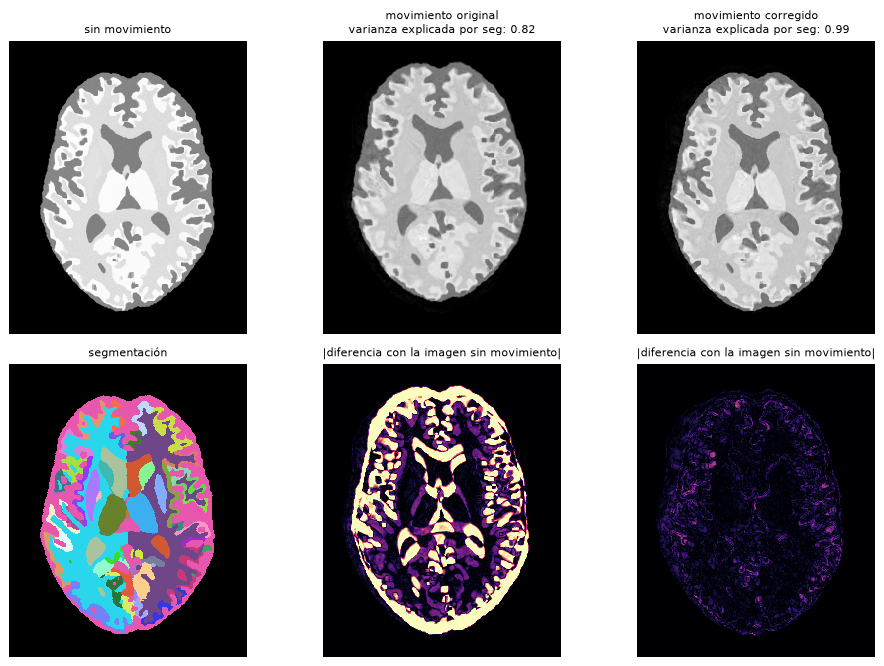

varianza explicada sin movimiento: 0.995


In [28]:
def motion_original(gen, img):
    """_motion SIN la corrección: todos los disparos se mueven (cornucopia tal cual)."""
    cfg = gen.cfg
    axis = random.choice([1, 2, 3])
    img = img.movedim(axis, 1)
    n = img.shape[1]
    fov_mm = min(img.shape[1:]) * cfg.target_voxel
    length = math.ceil(n / cfg.motion_shots)
    pattern = torch.zeros([cfg.motion_shots, n, 1, 1], dtype=torch.bool, device=img.device)
    for shot in range(cfg.motion_shots):
        pattern[shot, shot * length:(shot + 1) * length] = True
    motion = cc.IntraScanMotionTransform(
        shots=cfg.motion_shots, axis=1, translations=cfg.motion_translations_mm / fov_mm,
        rotations=cfg.motion_rotations, pattern=pattern)
    return motion(img).movedim(1, axis)

prob, gen.cfg.motion_prob = gen.cfg.motion_prob, 1.0     # forzamos el movimiento
outs = {}
with torch.no_grad():
    for name, fn in [('original', lambda x: motion_original(gen, x)),
                     ('corregido', gen._motion)]:
        random.seed(3)
        torch.manual_seed(3)
        if name == 'original':
            random.random()      # _motion consume primero un número (¿se aplica?): igualamos
        outs[name] = fn(img_bias)
gen.cfg.motion_prob = prob

seg_np = seg_lr.cpu().numpy()
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5))
show(axes[0, 0], axial(img_bias[0].cpu(), aff_lr, point), 'sin movimiento')
show(axes[1, 0], axial(seg_lr.cpu(), aff_lr, point), 'segmentación', **lkw)
for j, name in enumerate(['original', 'corregido']):
    m = outs[name][0].cpu()
    ev = explained_variance(m.numpy(), seg_np)
    show(axes[0, j + 1], axial(m, aff_lr, point), f'movimiento {name}\nvarianza explicada por seg: {ev:.2f}')
    show(axes[1, j + 1], axial((m - img_bias[0].cpu()).abs(), aff_lr, point),
         '|diferencia con la imagen sin movimiento|', cmap='magma', vmin=0, vmax=0.3)
fig.tight_layout()
plt.show()
print('varianza explicada sin movimiento:', round(explained_variance(img_bias[0].cpu().numpy(), seg_np), 3))

- **original**: la diferencia es grande en todos los bordes → la anatomía entera se ha movido y la segmentación ya no le corresponde.
- **corregido**: la diferencia es sólo el *ghosting* (réplicas tenues) y algo de emborronamiento; los bordes siguen donde dice la segmentación.

El movimiento se aplica con probabilidad `motion_prob` = 0.3. (En el código hay además dos *workarounds* para cornucopia 0.5.1 con volúmenes no cúbicos: mover el eje elegido a la dimensión 1 y pasar el patrón con forma `(shots, n, 1, 1)`.)

### 9.3 Ruido y normalización

- **Ruido gaussiano** aditivo con σ ~ U(0.01, 0.1) (`noise_sigma`), sobre una imagen con intensidades del orden de [0, 1].
- **Min-max**: la imagen final se lleva a [0, 1].

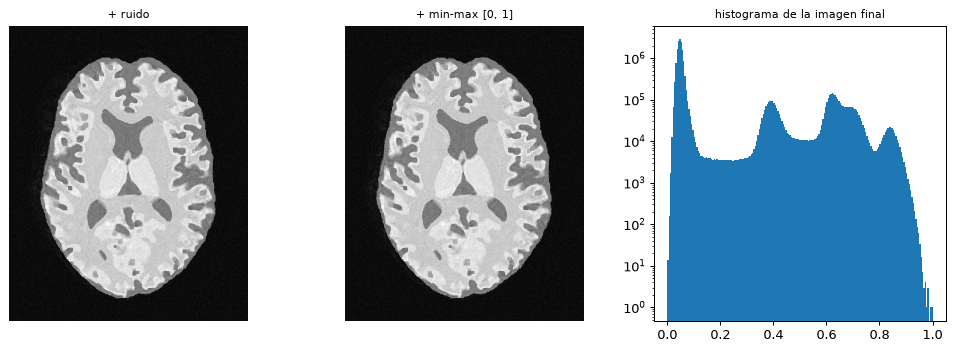

In [29]:
torch.manual_seed(0)
with torch.no_grad():
    img_noise = gen.noise(outs['corregido'])
    img_final = gen.normalize(img_noise)
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
show(axes[0], axial(img_noise[0].cpu(), aff_lr, point), '+ ruido')
show(axes[1], axial(img_final[0].cpu(), aff_lr, point), '+ min-max [0, 1]')
axes[2].hist(img_final[0].cpu().numpy().ravel(), bins=200, log=True)
axes[2].set_title('histograma de la imagen final', fontsize=9)
fig.tight_layout()
plt.show()

## 10. Todo junto

### 10.1 `gen()`

Una llamada a `gen()` hace los pasos 3–7 con valores aleatorios nuevos y devuelve:
- `img`: `(1, X, Y, Z)` en [0, 1], a 0.75 mm;
- `seg`: `(X, Y, Z)` con **índices** en `gen.labels` (no valores crudos);
- `affine`: la affine de la rejilla de 0.75 mm (`aff_hr · pool`);
- `info`: lo que se sorteó (`colors_mu`, `colors_sigma`, `resolution`, `contrast`, `mus`, `sigmas`) y las **clases de generación** (`group_of`, `class_names`).

Generamos varias muestras y comprobamos con la varianza explicada que imagen y segmentación están alineadas:

In [30]:
# print(gen.cfg)
# save the configuration used to generate the images
with open('data/outputs/config_used.json', 'w') as f:
    json.dump(gen.cfg.to_dict(), f, indent=2)

muestra 0 generada en 2.14 s, shape (1, 240, 296, 260), 19 clases
muestra 1 generada en 1.31 s, shape (1, 240, 296, 260), 52 clases
muestra 2 generada en 2.30 s, shape (1, 240, 296, 260), 19 clases
muestra 3 generada en 2.75 s, shape (1, 240, 296, 260), 12 clases


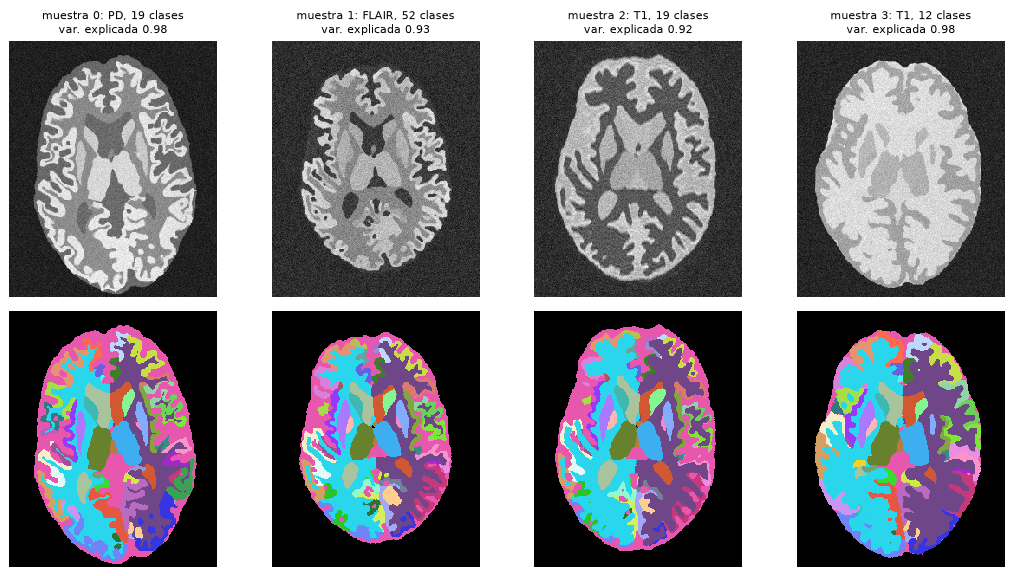

claves de info: ['colors_mu', 'colors_sigma', 'resolution', 'contrast', 'mus', 'sigmas', 'group_of', 'class_names', 'pv']


In [50]:
import time
tg.seed_everything(0)
samples = []
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for i in range(4):
    start = time.time()
    img_i, seg_i, aff_i, info_i = gen()
    print(f'muestra {i} generada en {time.time() - start:.2f} s, shape {tuple(img_i.shape)}, {len(info_i["class_names"])} clases')
    samples.append((img_i, seg_i, aff_i, info_i))
    ev = explained_variance(img_i[0].cpu().numpy(), seg_i.cpu().numpy())
    show(axes[0, i], axial(img_i[0].cpu(), aff_i, point),
         f'muestra {i}: {info_i["contrast"]}, {len(info_i["class_names"])} clases\nvar. explicada {ev:.2f}')
    show(axes[1, i], axial(seg_i.cpu(), aff_i, point), '', **lkw)
fig.tight_layout()
plt.show()
print('claves de info:', list(samples[0][3]))

### 10.2 Guardar las muestras

`save_sample` guarda imagen y segmentación en NIfTI con la misma affine. Con `labels=gen.labels`, los índices se convierten de vuelta a los **valores crudos** de FreeSurfer. El CLI (`python tree_generator.py --seg ... --tree ... --out ...`) escribe directamente un dataset con el formato de **nnU-Net** (`imagesTr/`, `labelsTr/`, `dataset.json`).

In [31]:
out_dir = tempfile.mkdtemp()
img_i, seg_i, aff_i, info_i = samples[0]
tg.save_sample(img_i, seg_i, aff_i, f'{out_dir}/img.nii.gz', f'{out_dir}/seg.nii.gz',
               labels=gen.labels)
saved = nib.load(f'{out_dir}/seg.nii.gz')
print('guardado:', saved.shape, 'vóxel', saved.header.get_zooms(), saved.get_data_dtype())
print('valores crudos guardados (primeros):', np.unique(np.asarray(saved.dataobj))[:15].tolist())

guardado: (240, 296, 260) vóxel (np.float32(0.75), np.float32(0.75), np.float32(0.75)) int16
valores crudos guardados (primeros): [0, 2, 4, 5, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18]


### 10.3 Usar las clases de generación en la *loss*

Si a la resolución sorteada dos etiquetas comparten gaussiana, la imagen **no contiene información** para separarlas, así que no es justo penalizar a la red por confundirlas. `info['group_of'][k]` da la clase de la etiqueta `k`: se pueden fusionar las etiquetas de la segmentación (y sumar las probabilidades de la predicción) por clase antes de calcular la *loss*.

Con `resolution = None` la fusión sería siempre a `target_voxel` (0.75 mm). Nuestra configuración tiene `"resolution": [0.75, 3.0]`, así que cada muestra sortea su propia resolución de fusión (por eso las muestras de 10.1 tienen 52, 19 o 12 clases):

resolución sorteada 1.60 mm -> 18 clases de generación


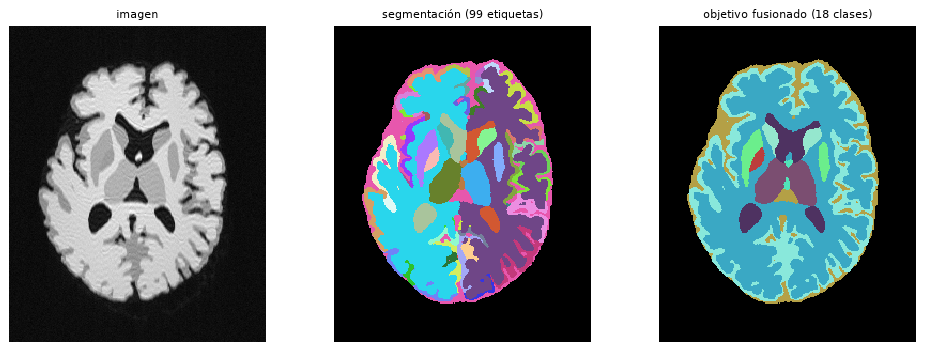

In [32]:
tg.seed_everything(1)
img_i, seg_i, aff_i, info_i = gen()

group_of = info_i['group_of']
seg_groups = group_of[seg_i.cpu().long().numpy()]      # segmentación fusionada por clase
G = len(info_i['class_names'])
print(f'resolución sorteada {info_i["resolution"]:.2f} mm -> {G} clases de generación')
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
show(axes[0], axial(img_i[0].cpu(), aff_i, point), 'imagen')
show(axes[1], axial(seg_i.cpu(), aff_i, point), f'segmentación ({gen.nb_labels} etiquetas)', **lkw)
show(axes[2], axial(seg_groups, aff_i, point), f'objetivo fusionado ({G} clases)',
     cmap=random_label_cmap(G, seed=2), vmin=0, vmax=G - 1)
fig.tight_layout()
plt.show()

# p. ej. para fusionar una predicción softmax (K, X, Y, Z) en (G, X, Y, Z):
#   M = torch.zeros(K, G); M[torch.arange(K), torch.as_tensor(group_of)] = 1
#   prob_groups = torch.einsum('kxyz,kg->gxyz', prob, M)

## 11. Resumen de parámetros y limitaciones

| paso | parámetros (`TreeGeneratorConfig`) | valor por defecto |
|---|---|---|
| rejillas | `target_voxel`, `factor` | 0.75 mm, 3 (HR = 0.25 mm) |
| etiquetas | `background`, `output_labels`, `unassigned` | 0, `'templates'`, `'error'` (`'background'` en el JSON) |
| 3. morfología | `morpho_pairs`, `morpho_iter`, `morpho_prob` | (del JSON), (1, 4), 0.5 |
| 4. deformación | `rotations`, `zooms`, `shears`, `translations_mm`, `elastic_dmax_mm`, `elastic_ctrl` | 10°, 0.1, 0, 0, 7.5 mm, 7 |
| 6. intensidades | `colors_mu`, `colors_sigma`, `min_sigma`, `intensity_scale`, `resolution`, `contrasts` | (0, 255), (0.255, 2.55), 0, 255, `None` (`[0.75, 3]` en el JSON), `None` (4 contrastes en el JSON) |
| 7. sesgo | `bias_prob`, `bias_vmax`, `bias_ctrl` | 1.0, 0.5, 5 |
| 7. movimiento | `motion_prob`, `motion_shots`, `motion_rotations`, `motion_translations_mm` | 0.3, 3, 10°, 10 mm |
| 7. ruido | `noise_sigma` | (0.01, 0.1) |

**Limitaciones actuales**
- `resolution` sólo controla la **fusión** de tejidos; la imagen siempre se genera a 0.75 mm sin simular el desenfoque de una adquisición más gruesa.
- `contrast` no cambia nada con este árbol (no hay `r_max` por contraste).
- El movimiento ya no desplaza la anatomía en bloque (el disparo central es la referencia). Si se quiere variar la posición global de la cabeza, debe hacerse en la deformación, que se aplica a la vez a imagen y etiquetas.
- Muchos valores (deformación, sesgo, movimiento) están marcados como `ASSUMPTION` en el código: son defaults razonables, no valores ajustados.